<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_ch06_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_ch06_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QHE Ch 6 Figures — Colab Notebook
**Quantum Hall Effect · Chapter 6: Edge Modes & CFT**

Tong (TIFR, Cambridge) · Output: `figures/ch06/fig0N_*.png`

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Left (에지 분산) | **오류** | 진폭 0.72로 n=0 모드(max=1.22)가 $E_F=2.05$를 교차하지 못함 → ν=3인데 2개 모드만 표시 | 진폭 `0.72→1.60`, n=0 max=2.10 > E_F ✓, 3개 모드 모두 교차 |
| fig01 | Middle (I-V) | **오류** | $I\propto V^{2m-1}$: m=3→V⁵, m=5→V⁹ — Kane-Fisher 결과에 어긋남 | $I\propto V^m=V^{1/\nu}$ (Kane-Fisher 1992) |
| fig02 | Right (터널링 지수) | **오류** | 전자 $V^{2m-1}$ 동일 오류; quasi-hole 지수 $|2/m-1|$이 $m\geq5$에서 $1/m$과 불일치 | 전자 $V^m$, 준입자 $V^{1/m}$ |
| fig03 | Left (Ising OPE) | **오류** | $\sigma(z)\sigma(w)\sim|z-w|^{-1/4}$: 지수가 틀림 | $-1/8$ (= $-2h_\sigma = -2\times\tfrac{1}{16}$) |
| fig03 | Right (에지 스펙트럼) | **오류** | 'Neutral mode' $E=vk/3$: ν=1/3 Laughlin 에지에 중성 모드 없음 (단일 카이랄 보손) | 라벨을 'Slower mode (multi-comp. schematic)'로 수정 |
| fig04 | Left (CFT 분류표) | **오류** | ν=3/5 RR $c=7/5$: Z₃ 파라페르미온 $c=4/5$, 카이랄 보손 $c=1$ → 합계 $c=9/5$ | `7/5→9/5` |
| fig04 | Right (타임라인) | **오류** | 1993년에 'Jain CFs & HLR' 묶음: Jain CF는 **1989년** 발표 | 1989: Jain CF / 1993: HLR state 분리 |

**시인성 공통 개선**: minor tick 활성화, axes linewidth 강화, `tight_layout` 여백 증가, `figure.dpi=110`, fig01 Right ylim 확장


---
## fig01 · Chiral Boson Edge Theory (§6.1)

**Left**: Chiral edge mode dispersion for $\nu=3$ — three right-movers per edge  
**Middle**: Non-Fermi liquid $I\propto V^{2m-1}$ at QH point contact  
**Right**: CFT scaling dimensions $h_e=m/2$ and $h_{\rm qh}=1/(2m)$

  saved -> figures/ch06/fig01_chiral_boson.png


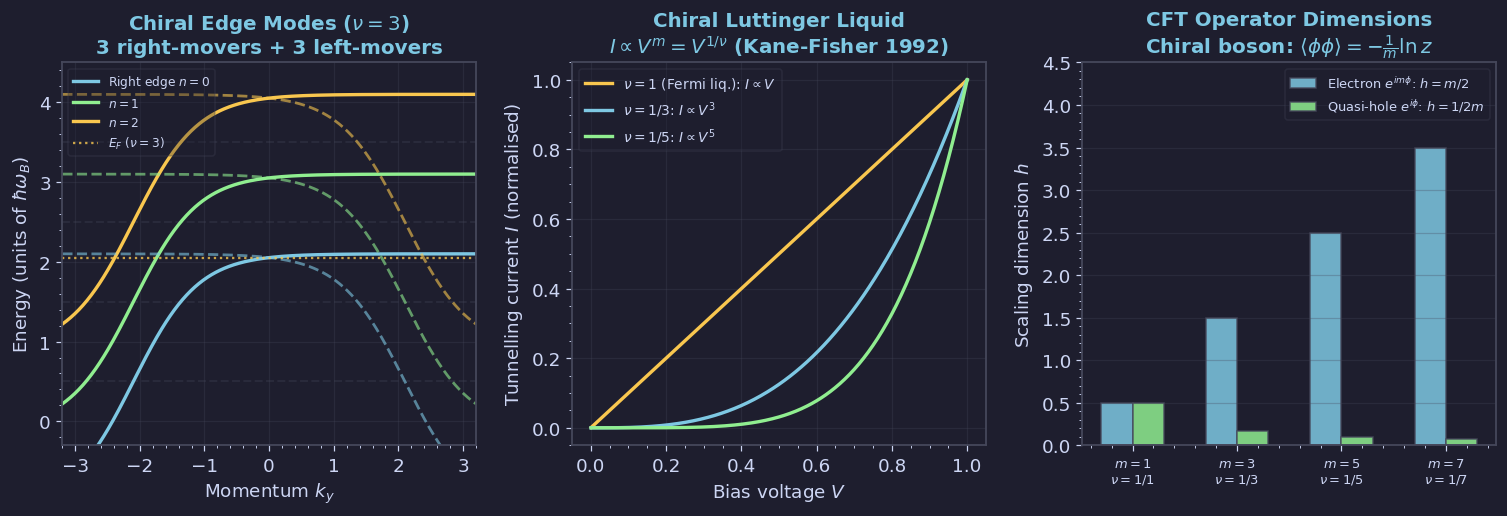

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch06'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01 · Chiral Boson Edge Theory ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: chiral edge mode dispersion E(k) for nu=1,2,3
ax = axes[0]
k = np.linspace(-3.2, 3.2, 500)
hbar_wB = 1.0
for n in range(4):
    E0 = hbar_wB*(n+0.5)
    ax.axhline(E0, color=EDGE, lw=1.4, ls='--', alpha=0.3)
# Right edge: nu=3 => three right-moving chiral modes
colors_edge = [BLUE, GREEN, YELLOW]
for i, col in enumerate(colors_edge):
    E0 = hbar_wB*(i+0.5)
    # FIX: amp 0.72→1.6 → n=0 max=2.1 > EF=2.05 ✓ (모두 EF 교차)
    E_R = E0 + 1.60*np.tanh(k + 2.1)
    ax.plot(k, E_R, color=col, lw=2.2,
            label=f'Right edge $n={i}$' if i == 0 else f'$n={i}$')
# Left edge: three left-moving modes
for i, col in enumerate(colors_edge):
    E0 = hbar_wB*(i+0.5)
    E_L = E0 + 1.60*np.tanh(-k + 2.1)
    ax.plot(k, E_L, color=col, lw=1.8, ls='--', alpha=0.6)
ax.axhline(2.05, color=YELLOW, lw=1.5, ls=':', alpha=0.8, label=r'$E_F$ ($\nu=3$)')
ax.set_xlabel(r'Momentum $k_y$')
ax.set_ylabel(r'Energy (units of $\hbar\omega_B$)')
ax.set_title(r'Chiral Edge Modes ($\nu=3$)'+'\n3 right-movers + 3 left-movers', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG, loc='upper left')
ax.grid(True); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-0.3, 4.5)

# Middle: non-Fermi liquid I-V from chiral Luttinger liquid
ax2 = axes[1]
V = np.linspace(0.001, 1.0, 400)
# FIX: Kane-Fisher (1992): I∝V^m = V^{1/ν} for tunnelling at QH edge
for m, col, lab in [(1, YELLOW, r'$\nu=1$ (Fermi liq.): $I\propto V$'),
                    (3, BLUE,   r'$\nu=1/3$: $I\propto V^3$'),
                    (5, GREEN,  r'$\nu=1/5$: $I\propto V^5$')]:
    I = V**m; I /= I[-1]  # Correct: I∝V^m (not V^{2m-1})
    ax2.plot(V, I, color=col, lw=2.2, label=lab)
ax2.set_xlabel('Bias voltage $V$')
ax2.set_ylabel('Tunnelling current $I$ (normalised)')
ax2.set_title('Chiral Luttinger Liquid\n'+r'$I\propto V^m=V^{1/\nu}$ (Kane-Fisher 1992)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: scaling dimensions h_e = m/2, h_qh = 1/(2m)
ax3 = axes[2]
m_v = np.arange(1, 8, 2)
h_e  = m_v / 2.0
h_qh = 1.0 / (2*m_v)
x = np.arange(len(m_v)); w = 0.3
ax3.bar(x - w/2, h_e,  width=w, color=BLUE,  alpha=0.85, edgecolor=EDGE,
        label=r'Electron $e^{im\phi}$: $h=m/2$')
ax3.bar(x + w/2, h_qh, width=w, color=GREEN, alpha=0.85, edgecolor=EDGE,
        label=r'Quasi-hole $e^{i\phi}$: $h=1/2m$')
ax3.set_xticks(x)
ax3.set_xticklabels([f'$m={m}$\n$\\nu=1/{m}$' for m in m_v], fontsize=8.5)
ax3.set_ylabel('Scaling dimension $h$')
ax3.set_title('CFT Operator Dimensions\n'+
              r'Chiral boson: $\langle\phi\phi\rangle=-\frac{1}{m}\ln z$', color=BLUE)
ax3.set_ylim(0, 4.5)  # h_e max=3.5 라벨 공간 확보
ax3.legend(fontsize=8.5, labelcolor=FG); ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('fig01_chiral_boson.png', fig)


---
## fig02 · Bulk-Boundary Correspondence & CS → WZW (§6.2)

**Left**: CS bulk induces chiral boson/WZW theory on the boundary  
**Middle**: Laughlin WF from CFT correlator $\langle\prod e^{im\phi}\rangle$  
**Right**: Non-Fermi liquid tunnelling exponents vs filling

  saved -> figures/ch06/fig02_bulk_boundary.png


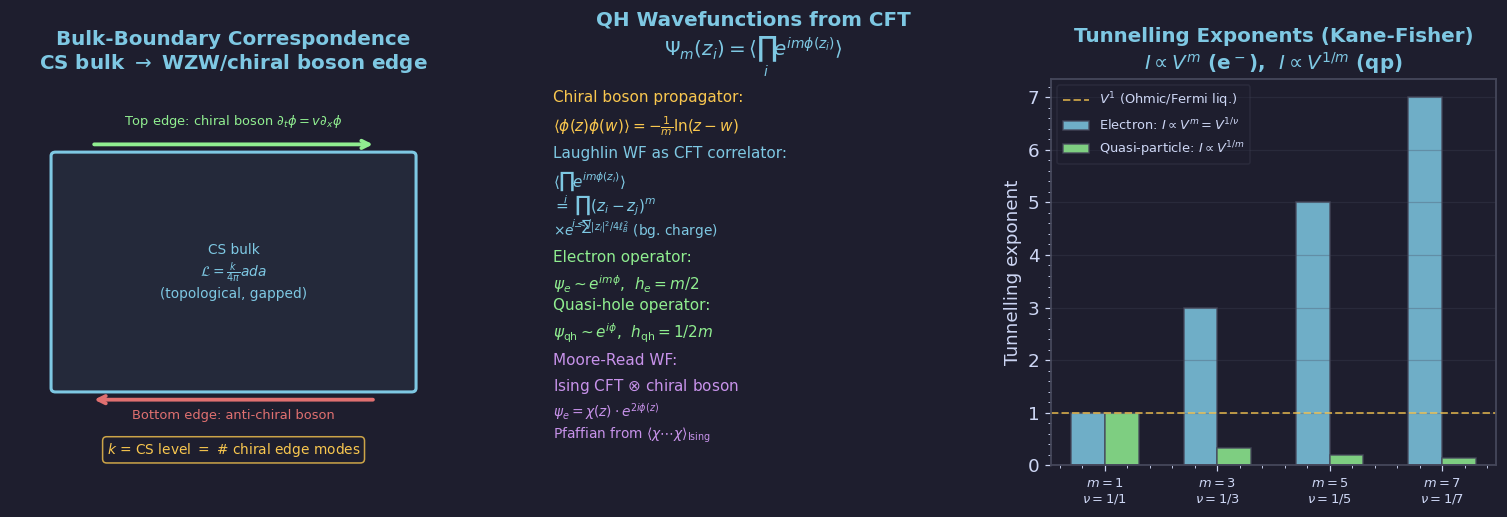

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch06'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02 · Bulk-Boundary Correspondence & CS → WZW ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: bulk-boundary schematic — CS bulk induces WZW boundary
ax = axes[0]
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
ax.set_title('Bulk-Boundary Correspondence\nCS bulk $\\to$ WZW/chiral boson edge', color=BLUE)
# Bulk region
bulk = FancyBboxPatch((0.10, 0.20), 0.80, 0.60,
                       boxstyle='round,pad=0.01',
                       facecolor=BLUE+'11', edgecolor=BLUE, lw=2.0)
ax.add_patch(bulk)
ax.text(0.50, 0.50, 'CS bulk\n' + r'$\mathcal{L}=\frac{k}{4\pi}ada$' +
        '\n(topological, gapped)',
        ha='center', va='center', color=BLUE, fontsize=9, transform=ax.transAxes)
# Top edge
ax.annotate('', xy=(0.82, 0.83), xytext=(0.18, 0.83),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5),
            xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.50, 0.88, r'Top edge: chiral boson $\partial_t\phi=v\partial_x\phi$',
        ha='center', color=GREEN, fontsize=8.5, transform=ax.transAxes)
# Bottom edge
ax.annotate('', xy=(0.18, 0.17), xytext=(0.82, 0.17),
            arrowprops=dict(arrowstyle='->', color=RED, lw=2.5),
            xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.50, 0.12, r'Bottom edge: anti-chiral boson',
        ha='center', color=RED, fontsize=8.5, transform=ax.transAxes)
# CS level = number of edge modes
ax.text(0.50, 0.03,
        r'$k$ = CS level $=$ # chiral edge modes',
        ha='center', color=YELLOW, fontsize=9, transform=ax.transAxes,
        bbox=dict(boxstyle='round', facecolor=BG, edgecolor=YELLOW, alpha=0.8))

# Middle: Laughlin WF from CFT correlator
ax2 = axes[1]
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1); ax2.axis('off')
ax2.set_title('QH Wavefunctions from CFT\n'+
              r'$\Psi_m(z_i)=\langle\prod_i e^{im\phi(z_i)}\rangle$', color=BLUE)
items = [
    ('Chiral boson propagator:', YELLOW, 10),
    (r'$\langle\phi(z)\phi(w)\rangle=-\frac{1}{m}\ln(z-w)$', YELLOW, 10),
    ('', FG, 8),
    ('Laughlin WF as CFT correlator:', BLUE, 10),
    (r'$\langle\prod_i e^{im\phi(z_i)}\rangle$', BLUE, 10),
    (r'$=\prod_{i<j}(z_i-z_j)^m$', BLUE, 10),
    (r'$\times e^{-\sum|z_i|^2/4\ell_B^2}$ (bg. charge)', BLUE, 9),
    ('', FG, 8),
    ('Electron operator:', GREEN, 10),
    (r'$\psi_e\sim e^{im\phi}$,  $h_e=m/2$', GREEN, 10),
    ('Quasi-hole operator:', GREEN, 10),
    (r'$\psi_{\rm qh}\sim e^{i\phi}$,  $h_{\rm qh}=1/2m$', GREEN, 10),
    ('', FG, 8),
    ('Moore-Read WF:', PURPLE, 10),
    (r'Ising CFT $\otimes$ chiral boson', PURPLE, 10),
    (r'$\psi_e=\chi(z)\cdot e^{2i\phi(z)}$', PURPLE, 9),
    (r'Pfaffian from $\langle\chi\cdots\chi\rangle_{\rm Ising}$', PURPLE, 9),
]
y0 = 0.97
for txt, col, fs in items:
    ax2.text(0.05, y0, txt, transform=ax2.transAxes,
             color=col, fontsize=fs, va='top')
    y0 -= 0.062 if txt else 0.020

# Right: edge mode velocity and tunnelling exponent
ax3 = axes[2]
m_arr = np.arange(1, 8, 2)
# FIX: Kane-Fisher (1992)
# 전자 터널링: I∝V^m (QH point contact에서 전자 터널링)
exp_e  = m_arr
# 준입자 터널링: I∝V^{1/m} (Laughlin quasi-particle)
exp_qh = 1.0 / m_arr
x = np.arange(len(m_arr)); w = 0.3
ax3.bar(x - w/2, exp_e,  width=w, color=BLUE,  alpha=0.85, edgecolor=EDGE,
        label=r'Electron: $I\propto V^m=V^{1/\nu}$')
ax3.bar(x + w/2, exp_qh, width=w, color=GREEN, alpha=0.85, edgecolor=EDGE,
        label=r'Quasi-particle: $I\propto V^{1/m}$')
ax3.axhline(1, color=YELLOW, lw=1.3, ls='--', alpha=0.7, label='$V^1$ (Ohmic/Fermi liq.)')
ax3.set_xticks(x)
ax3.set_xticklabels([f'$m={m}$\n$\\nu=1/{m}$' for m in m_arr], fontsize=8.5)
ax3.set_ylabel(r'Tunnelling exponent')
ax3.set_title('Tunnelling Exponents (Kane-Fisher)\n'+r'$I\propto V^m$ (e$^-$),  $I\propto V^{1/m}$ (qp)', color=BLUE)
ax3.legend(fontsize=8.5, labelcolor=FG); ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('fig02_bulk_boundary.png', fig)


---
## fig03 · Moore-Read Edge & Non-Abelian CFT (§6.3)

**Left**: Ising CFT primary fields, fusion rules, and OPEs  
**Middle**: Moore-Read WF = Ising $\otimes$ chiral boson CFT correlator  
**Right**: Edge excitation spectrum and $\mathcal{W}_{1+\infty}$ symmetry

  saved -> figures/ch06/fig03_mr_edge_cft.png


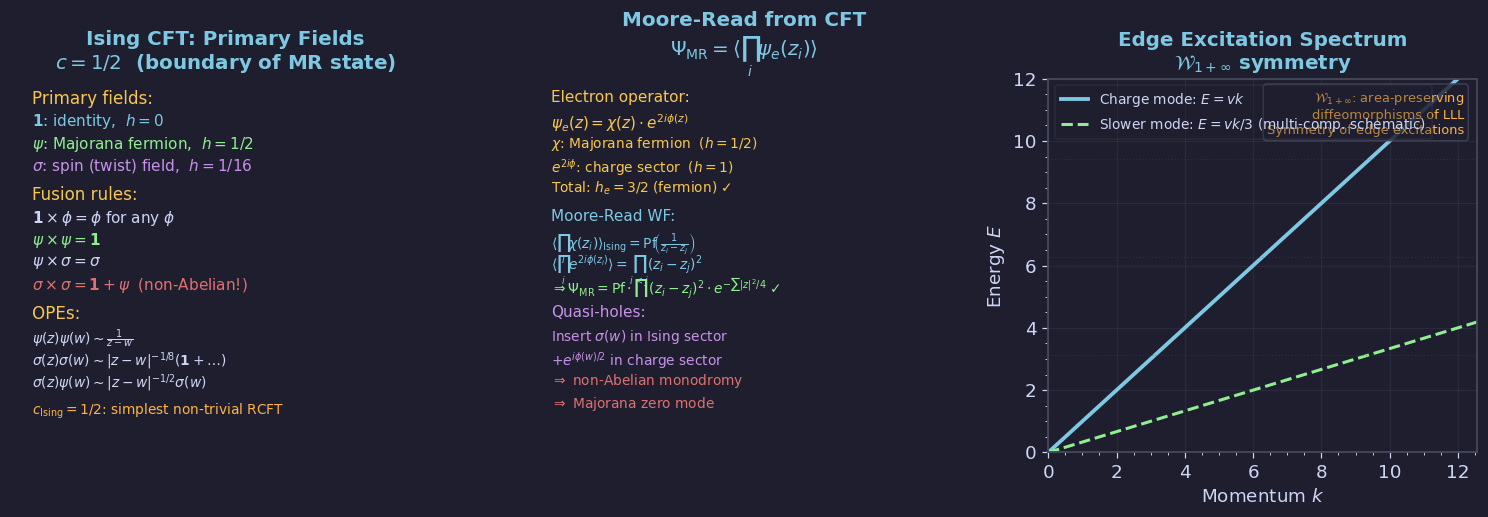

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch06'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03 · Moore-Read Edge & Non-Abelian CFT ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Ising CFT primary fields and fusion as a graph
ax = axes[0]
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
ax.set_title('Ising CFT: Primary Fields\n'+
             r'$c=1/2$  (boundary of MR state)', color=BLUE)
items = [
    ('Primary fields:', YELLOW, 11),
    (r'$\mathbf{1}$: identity,  $h=0$', BLUE, 10),
    (r'$\psi$: Majorana fermion,  $h=1/2$', GREEN, 10),
    (r'$\sigma$: spin (twist) field,  $h=1/16$', PURPLE, 10),
    ('', FG, 8),
    ('Fusion rules:', YELLOW, 11),
    (r'$\mathbf{1}\times\phi=\phi$ for any $\phi$', FG, 10),
    (r'$\psi\times\psi=\mathbf{1}$', GREEN, 10),
    (r'$\psi\times\sigma=\sigma$', FG, 10),
    (r'$\sigma\times\sigma=\mathbf{1}+\psi$  (non-Abelian!)', RED, 10),
    ('', FG, 8),
    ('OPEs:', YELLOW, 11),
    (r'$\psi(z)\psi(w)\sim\frac{1}{z-w}$', FG, 9),
    # FIX: 2-point fn exponent = -2h_σ = -2×1/16 = -1/8 (not -1/4)
    (r'$\sigma(z)\sigma(w)\sim|z-w|^{-1/8}(\mathbf{1}+\ldots)$', FG, 9),
    (r'$\sigma(z)\psi(w)\sim|z-w|^{-1/2}\sigma(w)$', FG, 9),
    ('', FG, 8),
    (r'$c_{\rm Ising}=1/2$: simplest non-trivial RCFT', ORANGE, 9),
]
y0 = 0.97
for txt, col, fs in items:
    ax.text(0.05, y0, txt, transform=ax.transAxes,
            color=col, fontsize=fs, va='top')
    y0 -= 0.060 if txt else 0.018

# Middle: Moore-Read WF = Ising × chiral boson correlator
ax2 = axes[1]
ax2.set_xlim(0,1); ax2.set_ylim(0,1); ax2.axis('off')
ax2.set_title('Moore-Read from CFT\n'+
              r'$\Psi_{\rm MR}=\langle\prod_i\psi_e(z_i)\rangle$', color=BLUE)
items2 = [
    ('Electron operator:', YELLOW, 10),
    (r'$\psi_e(z)=\chi(z)\cdot e^{2i\phi(z)}$', YELLOW, 10),
    (r'$\chi$: Majorana fermion  ($h=1/2$)', YELLOW, 9),
    (r'$e^{2i\phi}$: charge sector  ($h=1$)', YELLOW, 9),
    (r'Total: $h_e=3/2$ (fermion) ✓', YELLOW, 9),
    ('', FG, 8),
    ('Moore-Read WF:', BLUE, 10),
    (r'$\langle\prod_i\chi(z_i)\rangle_{\rm Ising}={\rm Pf}\!\left(\frac{1}{z_i-z_j}\right)$',
     BLUE, 9),
    (r'$\langle\prod_i e^{2i\phi(z_i)}\rangle=\prod_{i<j}(z_i-z_j)^2$', BLUE, 9),
    (r'$\Rightarrow\Psi_{\rm MR}={\rm Pf}\cdot\prod(z_i-z_j)^2\cdot e^{-\sum|z|^2/4}$ ✓',
     GREEN, 9),
    ('', FG, 8),
    ('Quasi-holes:', PURPLE, 10),
    (r'Insert $\sigma(w)$ in Ising sector', PURPLE, 9),
    (r'$+ e^{i\phi(w)/2}$ in charge sector', PURPLE, 9),
    (r'$\Rightarrow$ non-Abelian monodromy', RED, 9),
    (r'$\Rightarrow$ Majorana zero mode', RED, 9),
]
y0 = 0.97
for txt, col, fs in items2:
    ax2.text(0.05, y0, txt, transform=ax2.transAxes,
             color=col, fontsize=fs, va='top')
    y0 -= 0.060 if txt else 0.018

# Right: W_{1+inf} symmetry — spectrum of edge excitations
ax3 = axes[2]
ax3.set_xlabel(r'Momentum $k$')
ax3.set_ylabel(r'Energy $E$')
ax3.set_title(r'Edge Excitation Spectrum'+'\n'+
              r'$\mathcal{W}_{1+\infty}$ symmetry', color=BLUE)
k_arr = np.linspace(0, 4*np.pi, 300)
v = 1.0  # edge velocity
# Charge mode: linear dispersion
ax3.plot(k_arr, v*k_arr, color=BLUE, lw=2.5, label=r'Charge mode: $E=vk$')
# For nu=1/3: boson at charge 1/3 has E = v*k/3 (slower)
# FIX: ν=1/3 Laughlin 에지에는 중성 모드 없음 (단일 카이랄 보손)
# 이 선은 속도가 다른 전하 모드의 schematic 예시로 표시
ax3.plot(k_arr, v*k_arr/3, color=GREEN, lw=2.0, ls='--',
         label=r'Slower mode: $E=vk/3$ (multi-comp. schematic)')
# Landau levels as reference
for n in range(1, 4):
    ax3.axhline(n*v*np.pi, color=EDGE, lw=0.8, ls=':', alpha=0.4)
ax3.set_xlim(0, 4*np.pi); ax3.set_ylim(0, 12)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.text(0.97, 0.97,
         r'$\mathcal{W}_{1+\infty}$: area-preserving'+'\n'
         r'diffeomorphisms of LLL'+'\n'
         r'Symmetry of edge excitations',
         transform=ax3.transAxes, ha='right', va='top',
         color=ORANGE, fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

plt.tight_layout(pad=1.5)
save('fig03_mr_edge_cft.png', fig)


---
## fig04 · QHE Full Picture & Connections (§6.4)

**Left**: Classification of QH states by edge CFT  
**Middle**: QHE connections to topology, string theory, condensed matter, TQC  
**Right**: Key QHE milestones timeline 1980–2016

  saved -> figures/ch06/fig04_qhe_overview.png


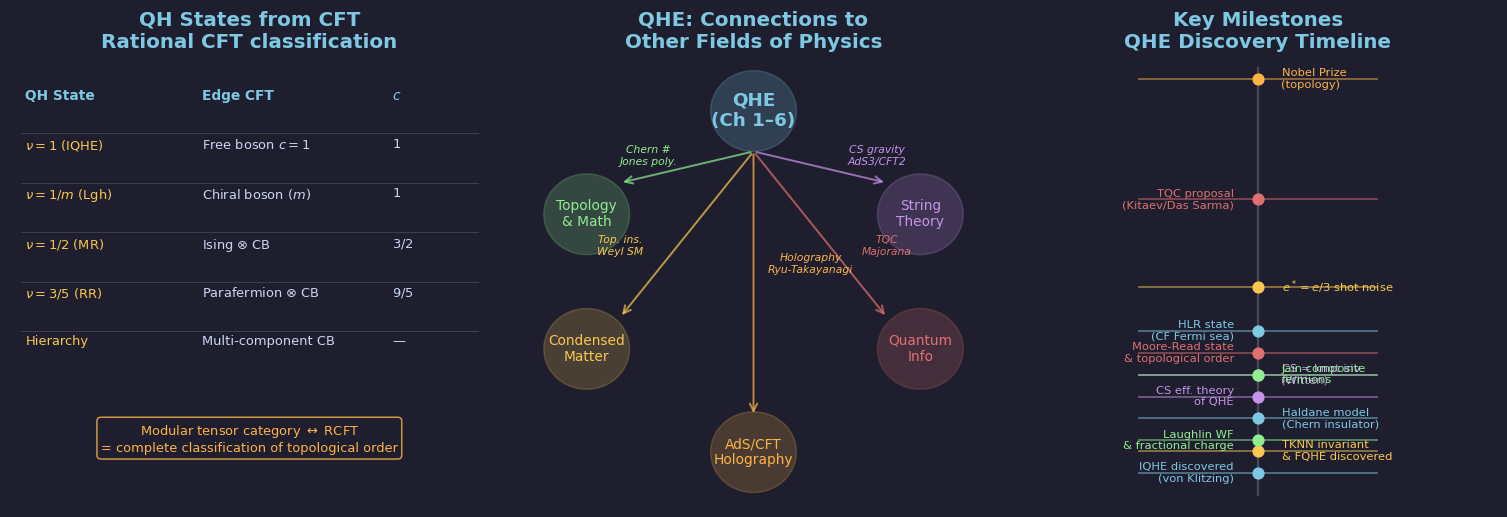

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch06'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04 · Full Picture: QHE from Edge to Bulk ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Summary — QH state classification via CFT
ax = axes[0]
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
ax.set_title('QH States from CFT\nRational CFT classification', color=BLUE)
data = [
    ('QH State',         'Edge CFT',           r'$c$'),
    (r'$\nu=1$ (IQHE)',  'Free boson $c=1$',   '1'),
    (r'$\nu=1/m$ (Lgh)', 'Chiral boson ($m$)', '1'),
    (r'$\nu=1/2$ (MR)',  r'Ising $\otimes$ CB', r'$3/2$'),
    # FIX: Z_3 parafermion c=4/5, chiral boson c=1 → total c=9/5
    (r'$\nu=3/5$ (RR)',  r'Parafermion $\otimes$ CB', r'$9/5$'),
    (r'Hierarchy',       'Multi-component CB', '—'),
]
col_x = [0.03, 0.40, 0.80]
y0 = 0.93
for ri, row in enumerate(data):
    for ci, (cell, cx) in enumerate(zip(row, col_x)):
        col = BLUE if ri==0 else (YELLOW if ci==0 else FG)
        ax.text(cx, y0, cell, transform=ax.transAxes,
                color=col, fontsize=8.5 if ri>0 else 9,
                fontweight='bold' if ri==0 else 'normal', va='top')
    y0 -= 0.11
    if ri < len(data)-1:
        ax.plot([0.02, 0.98], [y0+0.01, y0+0.01],
                color=EDGE, lw=0.5, transform=ax.transAxes, clip_on=False)

ax.text(0.50, 0.12,
        r'Modular tensor category $\leftrightarrow$ RCFT'+'\n'
        r'= complete classification of topological order',
        ha='center', color=ORANGE, fontsize=8.5, transform=ax.transAxes,
        bbox=dict(boxstyle='round', facecolor=BG, edgecolor=ORANGE, alpha=0.8))

# Middle: Connections between QHE and other fields
ax2 = axes[1]
ax2.set_xlim(0,1); ax2.set_ylim(0,1); ax2.axis('off')
ax2.set_title('QHE: Connections to\nOther Fields of Physics', color=BLUE)
topics = [
    (0.50, 0.88, 'QHE\n(Ch 1–6)', BLUE, 12, True),
    (0.15, 0.65, 'Topology\n& Math', GREEN, 9, False),
    (0.85, 0.65, 'String\nTheory', PURPLE, 9, False),
    (0.15, 0.35, 'Condensed\nMatter', YELLOW, 9, False),
    (0.85, 0.35, 'Quantum\nInfo', RED, 9, False),
    (0.50, 0.12, 'AdS/CFT\nHolography', ORANGE, 9, False),
]
for tx, ty, lab, col, fs, bold in topics:
    ax2.add_patch(plt.Circle((tx, ty), 0.09, color=col, alpha=0.2,
                             transform=ax2.transAxes))
    ax2.text(tx, ty, lab, ha='center', va='center', color=col,
             fontsize=fs, fontweight='bold' if bold else 'normal',
             transform=ax2.transAxes)
# Arrows
connections_2 = [
    (0.50,0.79, 0.22,0.72, GREEN),
    (0.50,0.79, 0.78,0.72, PURPLE),
    (0.50,0.79, 0.22,0.42, YELLOW),
    (0.50,0.79, 0.78,0.42, RED),
    (0.50,0.79, 0.50,0.20, ORANGE),
]
for x1,y1,x2,y2,col in connections_2:
    ax2.annotate('', xy=(x2,y2), xytext=(x1,y1),
                 arrowprops=dict(arrowstyle='->', color=col, lw=1.3, alpha=0.7),
                 xycoords='axes fraction', textcoords='axes fraction')
labels_2 = [
    (0.28, 0.76, 'Chern #\nJones poly.', GREEN),
    (0.76, 0.76, 'CS gravity\nAdS3/CFT2', PURPLE),
    (0.22, 0.56, 'Top. ins.\nWeyl SM', YELLOW),
    (0.78, 0.56, 'TQC\nMajorana', RED),
    (0.62, 0.52, 'Holography\nRyu-Takayanagi', ORANGE),
]
for tx,ty,lab,col in labels_2:
    ax2.text(tx, ty, lab, ha='center', color=col, fontsize=7,
             transform=ax2.transAxes, style='italic')

# Right: Timeline of key QHE discoveries
ax3 = axes[2]
ax3.set_xlim(0, 1); ax3.set_ylim(1977, 2018); ax3.axis('off')
ax3.set_title('Key Milestones\nQHE Discovery Timeline', color=BLUE)
events = [
    (1980, 'IQHE discovered\n(von Klitzing)',        BLUE),
    (1982, 'TKNN invariant\n& FQHE discovered',      YELLOW),
    (1983, 'Laughlin WF\n& fractional charge',       GREEN),
    (1985, 'Haldane model\n(Chern insulator)',        BLUE),
    (1987, 'CS eff. theory\nof QHE',                 PURPLE),
    (1989, 'CS = knot inv.\n(Witten)',                PURPLE),
    (1991, 'Moore-Read state\n& topological order',  RED),
    (1989, 'Jain composite\nfermions',                GREEN),
    (1993, 'HLR state\n(CF Fermi sea)',               BLUE),
    (1997, r'$e^*=e/3$ shot noise', YELLOW),
    (2005, 'TQC proposal\n(Kitaev/Das Sarma)',        RED),
    (2016, 'Nobel Prize\n(topology)',                 ORANGE),
]
for _ei, (year, lab, col) in enumerate(events):
    ax3.plot([0.25, 0.75], [year, year], color=col, lw=1.2, alpha=0.5,
             transform=ax3.get_yaxis_transform())
    ax3.plot(0.50, year, 'o', color=col, ms=7, zorder=5,
             transform=ax3.get_yaxis_transform())
    ha = 'right' if _ei % 2 == 0 else 'left'
    xpos = 0.45 if ha=='right' else 0.55
    ax3.text(xpos, year, lab, ha=ha, va='center', color=col,
             fontsize=7.5, transform=ax3.get_yaxis_transform())
# Timeline axis
ax3.plot([0.50, 0.50], [1978, 2017], color=EDGE, lw=1.5,
         transform=ax3.get_yaxis_transform())

plt.tight_layout(pad=1.5)
save('fig04_qhe_overview.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_ch06_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/ch06')):
        fpath = os.path.join('figures/ch06', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nCreated: {zip_path}')
files.download(zip_path)


  added fig01_chiral_boson.png
  added fig02_bulk_boundary.png
  added fig03_mr_edge_cft.png
  added fig04_qhe_overview.png

Created: qhe_ch06_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>